### Part A: Handling Missing Values

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer

# Matplotlib & Seaborn styling
plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)
%matplotlib inline

# Load dataset
df = pd.read_csv('patient_health_records.csv')
print(f'Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns')
df.head()


Dataset Shape: 1000 rows, 9 columns


,patient_id,age,gender,region,bmi,blood_pressure,cholesterol,glucose,disease_risk
0,PID_0001,69.0,Male,South,26.8,130.7,162.5,110.7,0
1,PID_0002,32.0,Female,East,28.4,127.4,205.8,124.4,0
2,PID_0003,78.0,Male,East,32.5,120.0,187.6,107.6,0
3,PID_0004,38.0,Male,East,20.1,109.5,195.3,85.1,1
4,PID_0005,41.0,Female,NaN,24.8,231.4,NaN,136.5,1


=== Missing Value Summary Report ===


,Data Type,Non-Null Count,Missing Count,Missing Percentage (%)
region,str,940,60,6.0
glucose,float64,940,60,6.0
cholesterol,float64,950,50,5.0
bmi,float64,950,50,5.0
age,float64,950,50,5.0
gender,str,960,40,4.0
patient_id,str,1000,0,0.0
blood_pressure,float64,1000,0,0.0
disease_risk,int64,1000,0,0.0


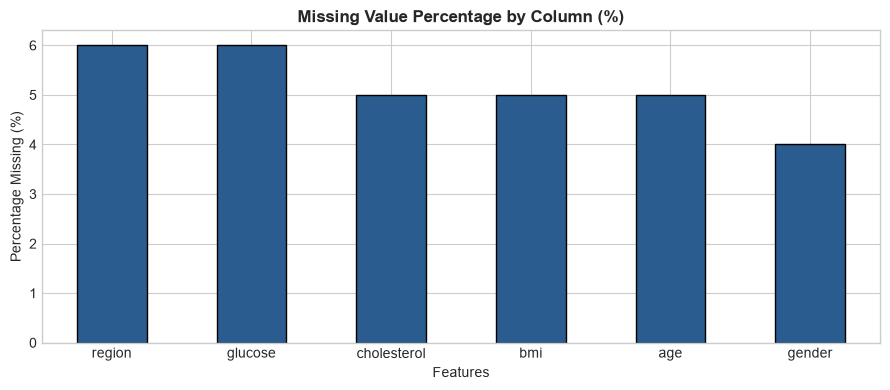

In [2]:
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df)) * 100

missing_report = pd.DataFrame({
    'Data Type': df.dtypes,
    'Non-Null Count': df.notnull().sum(),
    'Missing Count': missing_counts,
    'Missing Percentage (%)': missing_pct.round(2),
}).sort_values(by='Missing Count', ascending=False)

print('=== Missing Value Summary Report ===')
display(missing_report)

# Missingness bar chart
plt.figure(figsize=(9, 4))
missing_report[missing_report['Missing Count'] > 0][
    'Missing Percentage (%)'
].plot(kind='bar', color='#2b5c8f', edgecolor='black')
plt.title(
    'Missing Value Percentage by Column (%)', fontsize=12, fontweight='bold'
)
plt.ylabel('Percentage Missing (%)')
plt.xlabel('Features')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [3]:
imp_mean = SimpleImputer(strategy='mean')
imp_median = SimpleImputer(strategy='median')

df['bmi_mean_imp'] = imp_mean.fit_transform(df[['bmi']])
df['bmi_median_imp'] = imp_median.fit_transform(df[['bmi']])

print(
    f"Original BMI Mean:   {df['bmi'].mean():.3f} | Imputed Mean:  "
    f" {df['bmi_mean_imp'].mean():.3f}"
)
print(
    f"Original BMI Median: {df['bmi'].median():.3f} | Imputed Median:"
    f" {df['bmi_median_imp'].median():.3f}"
)

Original BMI Mean:   26.506 | Imputed Mean:   26.506
Original BMI Median: 26.500 | Imputed Median: 26.500


In [4]:
imp_mode = SimpleImputer(strategy='most_frequent')

print('--- Pre-Imputation Category Counts ---')
print('Region counts:\n', df['region'].value_counts(dropna=False))
print('\nGender counts:\n', df['gender'].value_counts(dropna=False))

# Apply Most Frequent Imputation
df['region_mode_imp'] = imp_mode.fit_transform(df[['region']])
df['gender_mode_imp'] = imp_mode.fit_transform(df[['gender']])

print('\n--- Post-Imputation Category Counts ---')
print('Region (Imputed):\n', df['region_mode_imp'].value_counts())
print('\nGender (Imputed):\n', df['gender_mode_imp'].value_counts())

--- Pre-Imputation Category Counts ---
Region counts:
 region
North    382
South    228
East     210
West     120
NaN       60
Name: count, dtype: int64

Gender counts:
 gender
Female    495
Male      465
NaN        40
Name: count, dtype: int64


ValueError: Buffer has wrong number of dimensions (expected 1, got 2)

In [5]:
# 1. Missing Indicator Flag
df['bmi_was_missing'] = df['bmi'].isnull().astype(int)

# 2. Random Sample Imputation
df['bmi_random_sample'] = df['bmi'].copy()
missing_mask = df['bmi'].isnull()
n_missing = missing_mask.sum()

random_draws = (
    df['bmi'].dropna().sample(n=n_missing, replace=True, random_state=42)
)
random_draws.index = df[missing_mask].index

df.loc[missing_mask, 'bmi_random_sample'] = random_draws

print('Missing indicator counts:')
print(df['bmi_was_missing'].value_counts())
print('\nDescriptive statistics:')
display(df[['bmi', 'bmi_random_sample']].describe())

Missing indicator counts:
bmi_was_missing
0    950
1     50
Name: count, dtype: int64

Descriptive statistics:


,bmi,bmi_random_sample
count,950.000000,1000.000000
mean,26.506000,26.489400
std,6.143642,6.100221
min,9.000000,9.000000
25%,23.100000,23.100000
50%,26.500000,26.450000
75%,29.600000,29.600000
max,73.600000,73.600000


In [6]:
num_cols = [
    'age',
    'bmi',
    'blood_pressure',
    'cholesterol',
    'glucose',
    'disease_risk',
]

knn_imputer = KNNImputer(n_neighbors=5)
knn_imputed_array = knn_imputer.fit_transform(df[num_cols])

df_knn = pd.DataFrame(
    knn_imputed_array, columns=[f'{col}_knn' for col in num_cols]
)
df['bmi_knn_imp'] = df_knn['bmi_knn']

missing_indices = df[df['bmi'].isnull()].index[:5]
display(df.loc[missing_indices, ['bmi', 'bmi_knn_imp']])

,bmi,bmi_knn_imp
22,NaN,25.54
29,NaN,28.04
42,NaN,27.00
45,NaN,28.46
51,NaN,22.30


In [7]:
mice_imputer = IterativeImputer(max_iter=10, random_state=42)
mice_imputed_array = mice_imputer.fit_transform(df[num_cols])

df_mice = pd.DataFrame(
    mice_imputed_array, columns=[f'{col}_mice' for col in num_cols]
)
df['bmi_mice_imp'] = df_mice['bmi_mice']

display(df.loc[missing_indices, ['bmi', 'bmi_knn_imp', 'bmi_mice_imp']])

,bmi,bmi_knn_imp,bmi_mice_imp
22,NaN,25.54,26.689502
29,NaN,28.04,27.031209
42,NaN,27.00,25.641128
45,NaN,28.46,26.728653
51,NaN,22.30,26.376258


=== Method Comparison Table ===


,Imputation Method,Count,Mean,Std Dev,Median,IQR
0,Original (Observed),950,26.506,6.144,26.500,6.500
1,Mean Imputation,1000,26.506,5.988,26.506,6.125
2,Median Imputation,1000,26.506,5.988,26.500,6.125
3,Random Sample (+ Flag),1000,26.489,6.100,26.450,6.500
4,KNN Imputer (k=5),1000,26.523,6.032,26.500,6.400
5,MICE (Chained Eq),1000,26.501,5.989,26.450,6.125


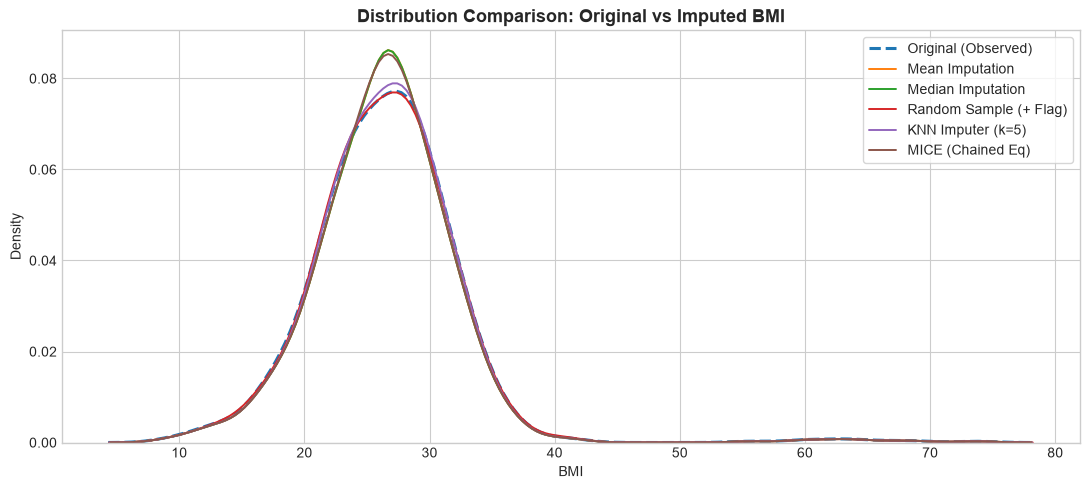

In [8]:
methods = {
    'Original (Observed)': df['bmi'].dropna(),
    'Mean Imputation': df['bmi_mean_imp'],
    'Median Imputation': df['bmi_median_imp'],
    'Random Sample (+ Flag)': df['bmi_random_sample'],
    'KNN Imputer (k=5)': df['bmi_knn_imp'],
    'MICE (Chained Eq)': df['bmi_mice_imp'],
}

records = []
for name, s in methods.items():
  records.append({
      'Imputation Method': name,
      'Count': int(s.count()),
      'Mean': round(s.mean(), 3),
      'Std Dev': round(s.std(), 3),
      'Median': round(s.median(), 3),
      'IQR': round(s.quantile(0.75) - s.quantile(0.25), 3),
  })

comparison_df = pd.DataFrame(records)
print('=== Method Comparison Table ===')
display(comparison_df)

# Density Plot (KDE)
plt.figure(figsize=(11, 5))
for name, s in methods.items():
  sns.kdeplot(
      s,
      label=name,
      lw=2.2 if 'Original' in name else 1.4,
      ls='--' if 'Original' in name else '-',
  )

plt.title(
    'Distribution Comparison: Original vs Imputed BMI',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel('BMI')
plt.ylabel('Density')
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

### Part B: Handling Outliers

In [9]:
# --- 1. Z-Score Method on Cholesterol and Glucose (|Z| > 3) ---
mean_chol, std_chol = df['cholesterol'].mean(), df['cholesterol'].std()
mean_gluc, std_gluc = df['glucose'].mean(), df['glucose'].std()

z_chol = (df['cholesterol'] - mean_chol).abs() / std_chol
z_gluc = (df['glucose'] - mean_gluc).abs() / std_gluc

outliers_z_chol = df[z_chol > 3]
outliers_z_gluc = df[z_gluc > 3]

print(f"Z-score outliers in Cholesterol (|z| > 3): {len(outliers_z_chol)}")
print(f"Z-score outliers in Glucose (|z| > 3):     {len(outliers_z_gluc)}")

# --- 2. IQR Method on BMI ---
q1_bmi = df['bmi'].quantile(0.25)
q3_bmi = df['bmi'].quantile(0.75)
iqr_bmi = q3_bmi - q1_bmi
lower_bmi = q1_bmi - 1.5 * iqr_bmi
upper_bmi = q3_bmi + 1.5 * iqr_bmi

outliers_iqr_bmi = df[(df['bmi'] < lower_bmi) | (df['bmi'] > upper_bmi)]
print(f"IQR bounds for BMI: [{lower_bmi:.2f}, {upper_bmi:.2f}]")
print(f"IQR outliers in BMI: {len(outliers_iqr_bmi)}")

# Combine all outlier row indices and drop them (Trimming)
outlier_indices = set(outliers_z_chol.index) | set(outliers_z_gluc.index) | set(outliers_iqr_bmi.index)
print(f"\nTotal unique outlier rows to remove: {len(outlier_indices)}")

df_trimmed = df.drop(index=list(outlier_indices)).copy()
print(f"Dataset shape before removal: {df.shape}")
print(f"Dataset shape after removal:  {df_trimmed.shape}")

Z-score outliers in Cholesterol (|z| > 3): 11
Z-score outliers in Glucose (|z| > 3):     10
IQR bounds for BMI: [13.35, 39.35]
IQR outliers in BMI: 26

Total unique outlier rows to remove: 47
Dataset shape before removal: (1000, 15)
Dataset shape after removal:  (953, 15)


In [10]:
# --- 1. Percentile Capping (1st & 99th percentile) ---
df_capped = df.copy()
num_vars = ['bmi', 'cholesterol', 'glucose']

for col in num_vars:
    p01 = df[col].quantile(0.01)
    p99 = df[col].quantile(0.99)
    df_capped[col] = df_capped[col].clip(lower=p01, upper=p99)

# --- 2. Winsorization (5% - 95% tails) ---
df_winsorized = df.copy()
for col in num_vars:
    p05 = df[col].quantile(0.05)
    p95 = df[col].quantile(0.95)
    df_winsorized[col] = df_winsorized[col].clip(lower=p05, upper=p95)

print("Percentile capping (1%-99%) and Winsorization (5%-95%) completed successfully.")

Percentile capping (1%-99%) and Winsorization (5%-95%) completed successfully.


### Part C: Final Clean Dataset

In [12]:
# Clean pipeline execution
raw_df = pd.read_csv('patient_health_records.csv')
clean_df = raw_df.copy()

# 1. Mode Imputation for Categorical columns
for cat_col in ['gender', 'region']:
  clean_df[cat_col] = clean_df[cat_col].fillna(clean_df[cat_col].mode()[0])

# 2. Multivariate MICE Imputation for Numerical columns
continuous_cols = [
    'age',
    'bmi',
    'blood_pressure',
    'cholesterol',
    'glucose',
    'disease_risk',
]
mice_pipeline = IterativeImputer(max_iter=10, random_state=42)
clean_df[continuous_cols] = mice_pipeline.fit_transform(
    clean_df[continuous_cols]
)

# 3. Percentile Capping (1st and 99th percentile) to control outliers
for col in ['bmi', 'cholesterol', 'glucose']:
  p01 = clean_df[col].quantile(0.01)
  p99 = clean_df[col].quantile(0.99)
  clean_df[col] = clean_df[col].clip(lower=p01, upper=p99).round(1)

clean_df['age'] = clean_df['age'].round(1)
clean_df['disease_risk'] = clean_df['disease_risk'].astype(int)

# Verify zero missing values
print(f'Remaining Missing Values: {clean_df.isnull().sum().sum()}')
print(
    f'Final Cleaned Dataset Dimensions: {clean_df.shape[0]} rows,'
    f' {clean_df.shape[1]} columns'
)

Remaining Missing Values: 0
Final Cleaned Dataset Dimensions: 1000 rows, 9 columns


In [13]:
# Save to CSV
clean_df.to_csv('cleaned_patient_health_records.csv', index=False)
print('File successfully exported: cleaned_patient_health_records.csv')

# Display first 10 rows
print('\n--- First 10 Cleaned Patient Records ---')
display(clean_df.head(10))

# Display complete descriptive statistics
print('\n--- Final Clean Dataset Summary Statistics ---')
display(clean_df.describe().round(2))

File successfully exported: cleaned_patient_health_records.csv

--- First 10 Cleaned Patient Records ---


,patient_id,age,gender,region,bmi,blood_pressure,cholesterol,glucose,disease_risk
0,PID_0001,69.0,Male,South,26.8,130.7,162.5,110.7,0
1,PID_0002,32.0,Female,East,28.4,127.4,205.8,124.4,0
2,PID_0003,78.0,Male,East,32.5,120.0,187.6,107.6,0
3,PID_0004,38.0,Male,East,20.1,109.5,195.3,85.1,1
4,PID_0005,41.0,Female,North,24.8,231.4,176.7,136.5,1
5,PID_0006,48.2,Male,North,22.8,121.1,157.2,98.8,0
6,PID_0007,39.0,Male,East,28.3,115.5,208.4,102.9,0
7,PID_0008,70.0,Male,South,32.4,136.2,194.6,90.2,1
8,PID_0009,19.0,Female,North,23.6,121.0,184.3,82.7,1
9,PID_0010,47.0,Male,East,15.0,135.7,223.3,84.1,0



--- Final Clean Dataset Summary Statistics ---


,age,bmi,blood_pressure,cholesterol,glucose,disease_risk
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,50.71,26.31,123.21,196.50,102.14,0.30
std,19.27,4.95,18.49,31.65,18.90,0.46
min,18.00,12.90,70.20,119.30,57.00,0.00
25%,34.00,23.38,112.40,176.50,89.48,0.00
50%,50.00,26.45,122.40,196.80,101.85,0.00
75%,68.00,29.50,131.52,216.22,114.40,1.00
max,84.00,41.30,256.30,277.80,160.80,1.00


In [14]:
# Save to CSV
clean_df.to_csv('cleaned_patient_health_records.csv', index=False)
print('File successfully exported: cleaned_patient_health_records.csv')

# Display first 10 rows
print('\n--- First 10 Cleaned Patient Records ---')
display(clean_df.head(10))

# Display complete descriptive statistics
print('\n--- Final Clean Dataset Summary Statistics ---')
display(clean_df.describe().round(2))

File successfully exported: cleaned_patient_health_records.csv

--- First 10 Cleaned Patient Records ---


,patient_id,age,gender,region,bmi,blood_pressure,cholesterol,glucose,disease_risk
0,PID_0001,69.0,Male,South,26.8,130.7,162.5,110.7,0
1,PID_0002,32.0,Female,East,28.4,127.4,205.8,124.4,0
2,PID_0003,78.0,Male,East,32.5,120.0,187.6,107.6,0
3,PID_0004,38.0,Male,East,20.1,109.5,195.3,85.1,1
4,PID_0005,41.0,Female,North,24.8,231.4,176.7,136.5,1
5,PID_0006,48.2,Male,North,22.8,121.1,157.2,98.8,0
6,PID_0007,39.0,Male,East,28.3,115.5,208.4,102.9,0
7,PID_0008,70.0,Male,South,32.4,136.2,194.6,90.2,1
8,PID_0009,19.0,Female,North,23.6,121.0,184.3,82.7,1
9,PID_0010,47.0,Male,East,15.0,135.7,223.3,84.1,0



--- Final Clean Dataset Summary Statistics ---


,age,bmi,blood_pressure,cholesterol,glucose,disease_risk
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,50.71,26.31,123.21,196.50,102.14,0.30
std,19.27,4.95,18.49,31.65,18.90,0.46
min,18.00,12.90,70.20,119.30,57.00,0.00
25%,34.00,23.38,112.40,176.50,89.48,0.00
50%,50.00,26.45,122.40,196.80,101.85,0.00
75%,68.00,29.50,131.52,216.22,114.40,1.00
max,84.00,41.30,256.30,277.80,160.80,1.00


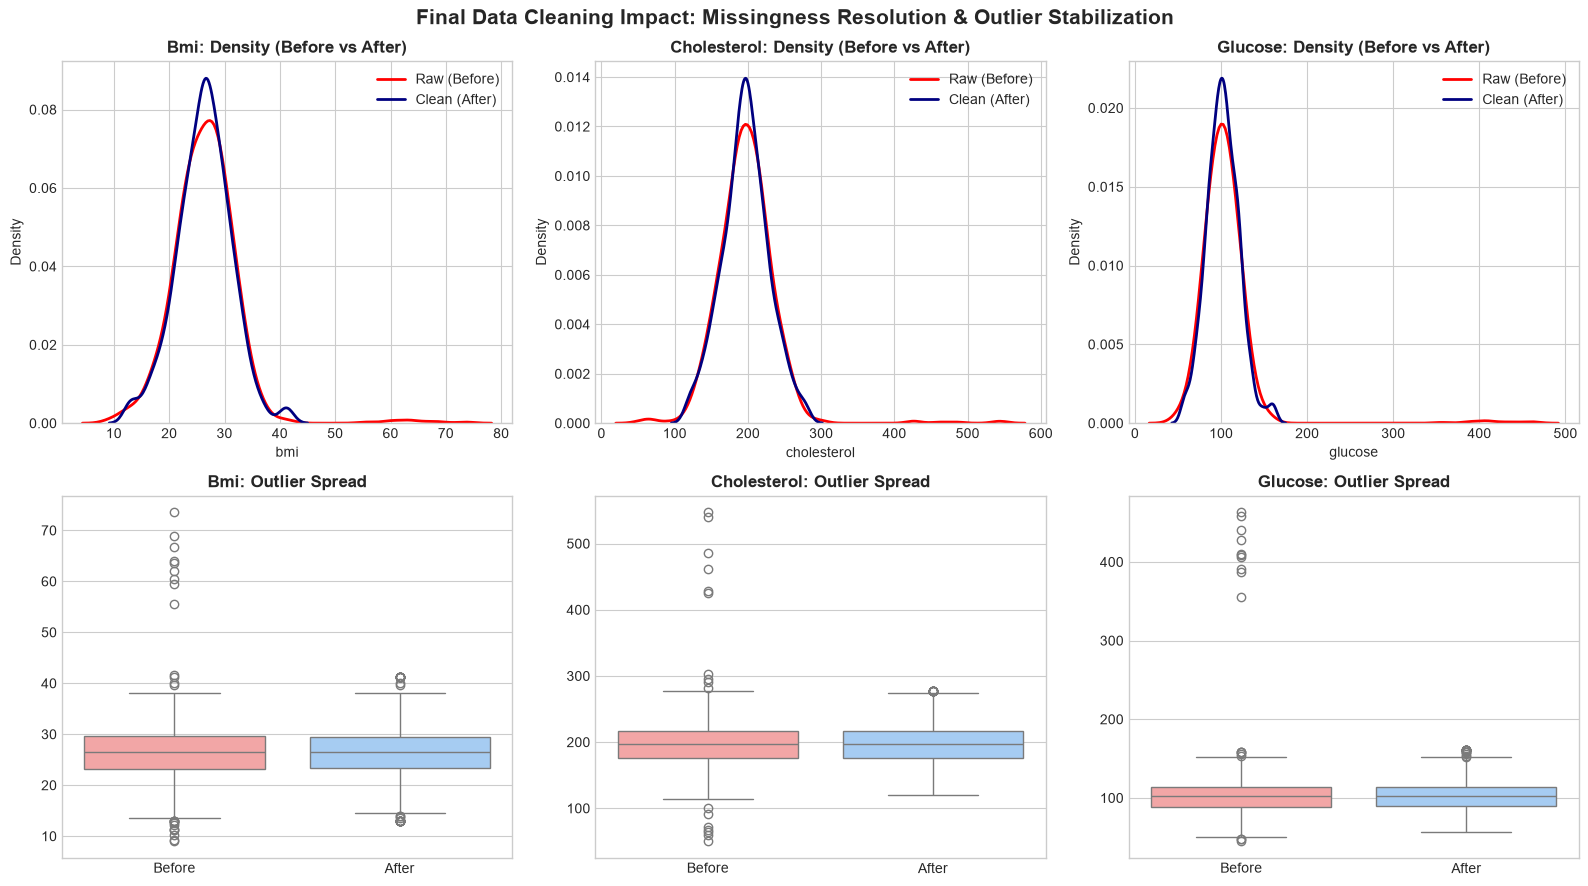

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

variables = ['bmi', 'cholesterol', 'glucose']
for i, var in enumerate(variables):
  # Density plot comparison
  sns.kdeplot(
      raw_df[var].dropna(),
      ax=axes[0, i],
      label='Raw (Before)',
      color='red',
      lw=2,
  )
  sns.kdeplot(
      clean_df[var], ax=axes[0, i], label='Clean (After)', color='navy', lw=2
  )
  axes[0, i].set_title(
      f'{var.capitalize()}: Density (Before vs After)', fontweight='bold'
  )
  axes[0, i].legend()

  # Boxplot comparison
  sns.boxplot(
      data=pd.DataFrame({'Before': raw_df[var], 'After': clean_df[var]}),
      ax=axes[1, i],
      palette=['#ff9999', '#99ccff'],
  )
  axes[1, i].set_title(f'{var.capitalize()}: Outlier Spread', fontweight='bold')

plt.suptitle(
    'Final Data Cleaning Impact: Missingness Resolution & Outlier'
    ' Stabilization',
    fontsize=15,
    fontweight='bold',
)
plt.tight_layout()
plt.show()